## **Лабораторная работа 2. Газовая динамика**

Реализовать полностью консервативную схему в переменных Лагранжа:
$u_t=-p_s$, $x_t=u$, $V_t=u_s$, $E_t=-p u_s$, $p=(\gamma-1)E/V$.

Берём пример из твоего notebook XYGEF: $L=1$, $T=0.12$, $N=200$, $M=80$,
$V_0=1$, $u_0=0$, $p_0=1+0.1e^{-((s-0.5)/0.12)^2}$.
Стенки неподвижны: $u(0,t)=u(1,t)=0$.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

Path('results').mkdir(exist_ok=True)
L, T, N, M = 1.0, 0.12, 200, 80
gamma = 1.4
h, tau = L / N, T / M
s = np.linspace(0, L, N + 1)
sc = 0.5 * (s[:-1] + s[1:])
t = np.linspace(0, T, M + 1)

### Сетка и начальные условия

X и U задаются в узлах, V, E и P — в центрах ячеек.
Первый индекс массива — номер временного слоя.

In [2]:
X = np.zeros((M + 1, N + 1))
U = np.zeros((M + 1, N + 1))
V = np.zeros((M + 1, N))
E = np.zeros((M + 1, N))
P = np.zeros((M + 1, N))
X[0] = s
V[0] = 1.0
P[0] = 1.0 + 0.1 * np.exp(-((sc - 0.5) / 0.12)**2)
E[0] = P[0] * V[0] / (gamma - 1)

### Метод прогонки

На каждом шаге Ньютона решаем трёхдиагональную систему $a_i y_{i-1}+b_i y_i+c_i y_{i+1}=d_i$.

In [3]:
def progonka(a, b, c, d):
    n = len(b)
    alpha, beta = np.zeros(n - 1), np.zeros(n)
    alpha[0] = c[0] / b[0]
    beta[0] = d[0] / b[0]
    # Прямой ход
    for i in range(1, n):
        z = b[i] - a[i-1] * alpha[i-1]
        if i < n - 1:
            alpha[i] = c[i] / z
        beta[i] = (d[i] - a[i-1] * beta[i-1]) / z
    # Обратный ход
    y = np.zeros(n)
    y[-1] = beta[-1]
    for i in range(n - 2, -1, -1):
        y[i] = beta[i] - alpha[i] * y[i+1]
    return y

### Полностью консервативная схема

Все временные средние берём с весом 1/2.
Исключаем давление через приращение объёма:
$\Delta V=\tau(\Delta u^{n+1}+\Delta u^n)/(2h)$,
$p^{n+1}=(\gamma-1)(E^n-p^n\Delta V/2)/(V^n+(\gamma+1)\Delta V/2)$.
Нелинейную систему по скорости решаем методом Ньютона.

In [4]:
mu = tau**2 / (4 * h**2)
newton_iterations = []
for j in range(M):
    v = U[j].copy()
    for k in range(20):
        dV = 0.5 * tau / h * (np.diff(v) + np.diff(U[j]))
        V1 = V[j] + dV
        D = V[j] + 0.5 * (gamma + 1) * dV
        B = (gamma - 1) * (E[j] - 0.5 * P[j] * dV)
        if min(V1.min(), D.min(), B.min()) <= 0:
            raise RuntimeError(f'Нефизическое состояние на слое {j}')
        p1 = B / D
        dp = -0.5 * ((gamma - 1) * P[j] + (gamma + 1) * p1) / D
        F = v[1:-1] - U[j, 1:-1] + 0.5 * tau / h * np.diff(p1 + P[j])
        if max(abs(F)) < 1e-12:
            break
        a = mu * dp[1:-1]
        b = 1 - mu * (dp[:-1] + dp[1:])
        v[1:-1] += progonka(a, b, a, -F)
    else:
        raise RuntimeError(f'Нет сходимости Ньютона на слое {j}')
    newton_iterations.append(k + 1)
    U[j+1] = v
    X[j+1] = X[j] + 0.5 * tau * (U[j] + v)
    V[j+1] = V1
    P[j+1] = p1
    E[j+1] = E[j] - 0.5 * (P[j] + p1) * dV

### Проверка сохранения энергии

$H=h\sum_i[E_i+(u_i^2+u_{i+1}^2)/4]$.
При неподвижных стенках поток энергии через края равен нулю.

In [5]:
rho = 1 / V
H = h * np.sum(E + 0.25 * (U[:, :-1]**2 + U[:, 1:]**2), axis=1)
err = abs(H / H[0] - 1)
geometry_error = np.max(abs(V - np.diff(X, axis=1) / h))
print('Максимальная ошибка энергии:', err.max())
print('Ошибка связи объёма и сетки:', geometry_error)
print('Минимальная плотность:', rho.min())
print('Минимальное давление:', P.min())
print('Итерации Ньютона на шаге:', min(newton_iterations), '—', max(newton_iterations))
assert err.max() < 1e-10 and geometry_error < 1e-10
assert rho.min() > 0 and P.min() > 0
np.savez('results/gas.npz', X=X, U=U, V=V, E=E, P=P, s=s, t=t,
         energy=H, energy_error=err)

Максимальная ошибка энергии: 5.551115123125783e-15
Ошибка связи объёма и сетки: 2.3359092438113294e-13
Минимальная плотность: 0.9503657331882646
Минимальное давление: 1.0000000034306396
Итерации Ньютона на шаге: 2 — 3


### Визуализация решения

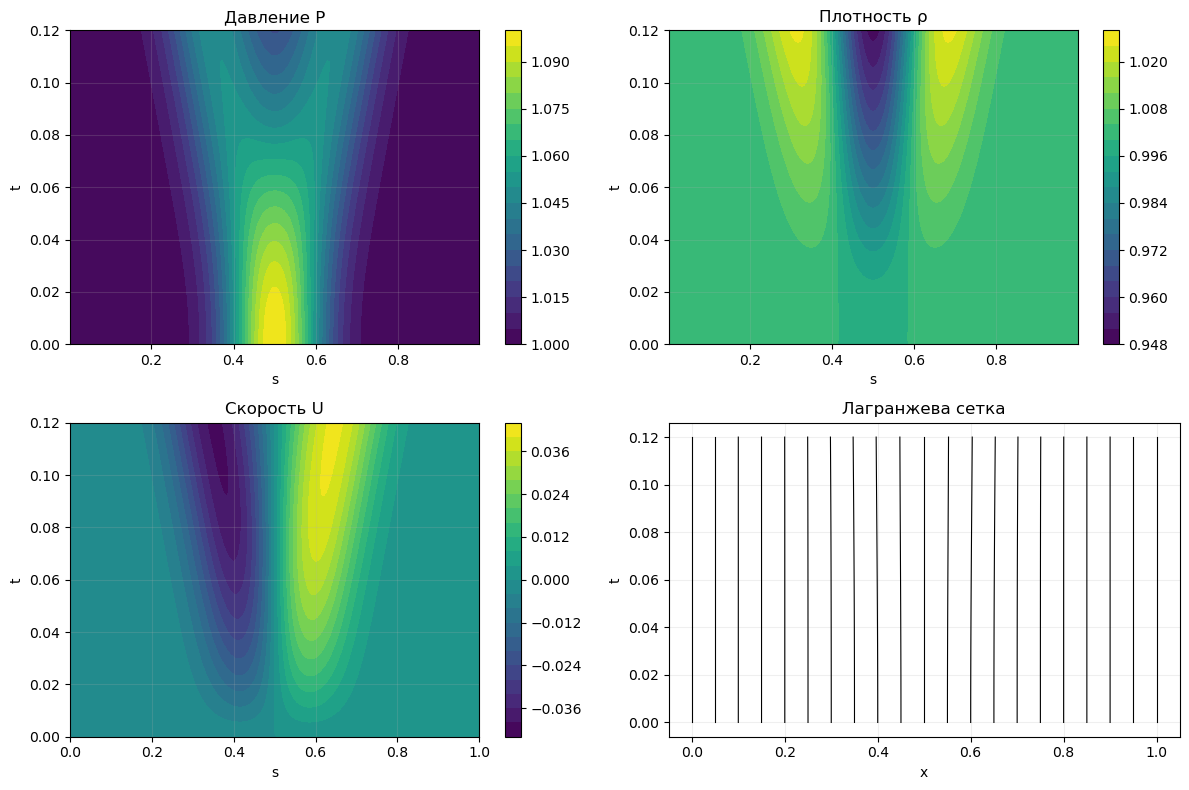

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for a, field, grid, title in [(ax[0,0], P, sc, 'Давление P'),
                             (ax[0,1], rho, sc, 'Плотность ρ'),
                             (ax[1,0], U, s, 'Скорость U')]:
    im = a.contourf(grid, t, field, levels=20)
    fig.colorbar(im, ax=a)
    a.set(title=title, xlabel='s', ylabel='t')
for i in range(0, N + 1, 10):
    ax[1,1].plot(X[:,i], t, lw=0.8, color='black')
ax[1,1].set(title='Лагранжева сетка', xlabel='x', ylabel='t')
for a in ax.flat:
    a.grid(alpha=0.2)
plt.tight_layout()
plt.savefig('results/gas.png', dpi=150)
plt.show()

### Анимация

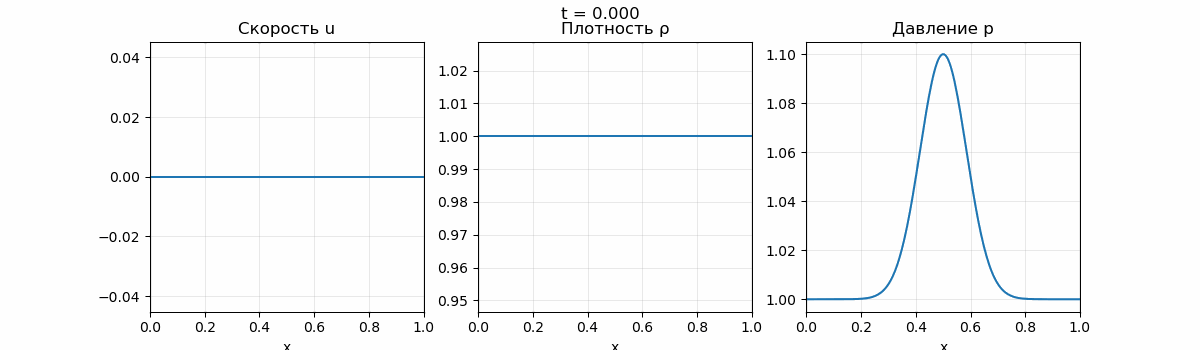

In [7]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
fields = [U, rho, P]
titles = ['Скорость u', 'Плотность ρ', 'Давление p']
lines = []
for a, field, title in zip(ax, fields, titles):
    line, = a.plot([], [])
    lines.append(line)
    d = max(0.05 * np.ptp(field), 1e-6)
    a.set(xlim=(0, L), ylim=(field.min()-d, field.max()+d), title=title, xlabel='x')
    a.grid(alpha=0.3)
label = fig.suptitle('')

def animate(j):
    xc = 0.5 * (X[j,:-1] + X[j,1:])
    for line, xx, field in zip(lines, [X[j], xc, xc], fields):
        line.set_data(xx, field[j])
    label.set_text(f't = {t[j]:.3f}')
    return lines

animation = FuncAnimation(fig, animate, frames=range(0, M+1, 2))
animation.save('results/gas.gif', writer=PillowWriter(fps=15))
plt.close(fig)
display(Image(filename='results/gas.gif'))

### Вывод

Начальное возмущение давления распадается на две расходящиеся волны.
Получены давление, плотность, скорость и движение сетки.
Полная энергия сохраняется с точностью решения нелинейной системы.
Рассмотрен гладкий пример; для сильных ударных волн потребуется искусственная вязкость.